# Adding risks: the simple sum, variance-covariance and a first diversification benefit

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 01 of topic 01 (open a committed artifact); no other topic is needed
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- read the four marginals of Banco Andino (credit, market, interest rate risk in the banking book and operational risk) from a committed document and say what its expected loss, VaR, expected shortfall and economic capital are;
- add the four capitals in the two simplest ways, the simple sum (perfect dependence) and the square-root rule with an inter-risk correlation matrix, and check both against the engine's committed band;
- say why a correlation matrix must be validated before it is used, and see the engine refuse three invalid ones;
- turn a total into a diversification factor and a benefit, see how the benefit shrinks to nothing as the correlation rises, and read the benefit that each risk gets;
- explain why the simple sum is not an upper bound for a VaR, with the committed worst case as evidence.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from riskvalidation.aggregation import simple
for name in ("riskvalidation", "numpy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

This notebook reads the capital-and-stress case of Contraste, **C18**: how much capital a bank needs once its risks are added up, and how much of the answer depends on the way they are added.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (the baseline scenario: its `outputs.aggregation` block holds the four marginals, the correlation matrix, the band of aggregation methods, the Euler allocation and the diversification) and `data/derived/C18/t-copula-baseline.json` (the same aggregation with the Rosenberg and Schuermann reference). Every path is relative to the repository root.
- **What the document does not hold:** the million simulated losses behind each marginal. It holds four summary numbers per marginal, which is all this notebook needs; notebooks 02 and 03 of this topic rebuild simulation from them.

The next cell finds the repository root (the notebook sits three folders below it) and defines a reader that stops with the file's path when a file is missing.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

derived folder found: True


## Method

### Step 1: the capital of each risk

Contraste measures every risk over **one year at the 99.9 percent level** and works with **economic capital**, the unexpected loss: the VaR of the loss distribution less its expected loss,

$$EC = \mathrm{VaR}_{0.999}(L) - \mathrm{EL}.$$

The expected shortfall (ES) is the mean loss beyond the VaR. The document holds the four numbers for each risk, in CLP millions. The next cell reads them, checks that $EC = \mathrm{VaR} - \mathrm{EL}$ holds in the document and prints the baking provenance.

In [3]:
# Read the baseline document, print the four marginals and check EC = VaR - EL for each
baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
print("capital basis:", agg["capital_basis"], "| horizon (years):", agg["horizon_years"], "| level:", agg["confidence_level"])
print("baked by riskvalidation", baseline["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print(f'{"risk":12s} {"EL":>10s} {"VaR":>10s} {"ES":>10s} {"EC":>10s}  EC = VaR - EL')
for m in agg["marginals"]:
    holds = bool(np.isclose(m["var_clp_m"] - m["el_clp_m"], m["ec_clp_m"]))
    print(f'{m["risk"]:12s} {m["el_clp_m"]:10,.0f} {m["var_clp_m"]:10,.0f} {m["es_clp_m"]:10,.0f} {m["ec_clp_m"]:10,.0f}  {holds}')

capital basis: economic-capital-var-less-el | horizon (years): 1 | level: 0.999
baked by riskvalidation 1.0.1 | installed 1.0.1
risk                 EL        VaR         ES         EC  EC = VaR - EL
credit           37,619    298,227    346,949    260,607  True
market                0    283,435    355,803    283,435  True
irrbb            27,922    100,746    106,382     72,824  True
operational       1,188     42,367    171,091     41,179  True


### Step 2: the simple sum

The simplest total adds the four capitals,

$$EC_{\text{tot}} = \sum_k EC_k.$$

It assumes the four bad years always come together (perfect dependence), and it is the **headline capital** of the case: the Chilean internal assessment adds up the capital needed for each risk. Every other figure of this notebook is information shown beside it, never a replacement. The next cell computes the sum with the engine's `simple_sum` and compares it with the headline the document states.

In [4]:
# Sum the four economic capitals with the engine and compare with the committed headline
risks = [m["risk"] for m in agg["marginals"]]
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
total_simple = simple.simple_sum(ec)
print("economic capitals:", {risk: round(float(value)) for risk, value in zip(risks, ec)})
print("simple sum (engine):", round(total_simple, 3))
print("committed headline :", round(agg["headline"]["capital_clp_m"], 3), "| method:", agg["headline"]["method"])
print("they agree:", bool(np.isclose(total_simple, agg["headline"]["capital_clp_m"])))

economic capitals: {'credit': 260607, 'market': 283435, 'irrbb': 72824, 'operational': 41179}
simple sum (engine): 658045.926
committed headline : 658045.926 | method: simple-sum
they agree: True


### Step 3: the inter-risk correlation matrix

Bad years do not always coincide, so a bank may add the capitals with a correlation matrix $R$ instead. The matrix of this case is a convention taken from Rosenberg and Schuermann (2006): market with credit 0.5, market and credit with operational risk 0.2, and the document extends the 0.5 to interest rate risk. A matrix is only usable if it is symmetric, has a unit diagonal, entries in $[-1, 1]$ and no negative eigenvalue (positive semi-definite). `check_correlation` checks all four and raises `ValueError` otherwise. The next cell prints the committed matrix, validates it, and shows three invalid matrices being refused. The messages are the engine's own, in English.

In [5]:
# Print the committed correlation matrix, validate it, and show three invalid matrices being refused
R = np.array(agg["correlation"]["matrix"])
print("order:", agg["correlation"]["order"], "| label:", agg["correlation"]["label"])
print(R)
simple.check_correlation(R)
print("the committed matrix passes check_correlation; smallest eigenvalue:", round(float(np.linalg.eigvalsh(R)[0]), 4))
invalid = {
    "not positive semi-definite": [[1, 0.9, -0.9], [0.9, 1, 0.9], [-0.9, 0.9, 1]],
    "not symmetric": [[1, 0.5], [0.2, 1]],
    "diagonal is not 1": [[2, 0.5], [0.5, 1]],
}
for why, matrix in invalid.items():
    try:
        simple.check_correlation(np.array(matrix, dtype=float))
        print(why, ": accepted")
    except ValueError as err:
        print(f"{why}: refused: {err}")

order: ['credit', 'market', 'irrbb', 'operational'] | label: convention
[[1.  0.5 0.5 0.2]
 [0.5 1.  0.5 0.2]
 [0.5 0.5 1.  0.2]
 [0.2 0.2 0.2 1. ]]
the committed matrix passes check_correlation; smallest eigenvalue: 0.5
not positive semi-definite: refused: corr must be positive semi-definite (smallest eigenvalue -0.8)
not symmetric: refused: corr must be symmetric
diagonal is not 1: refused: corr must have a unit diagonal


### Step 4: variance-covariance, the square-root rule

With a valid matrix the total capital is

$$EC_{\text{tot}} = \sqrt{EC^{\top} R \, EC} = \sqrt{\sum_{j}\sum_{k} R_{jk}\, EC_j\, EC_k}.$$

It is exact when the losses are elliptical with a common quantile scaling, and an approximation otherwise (dossier 05, G.1). Two limits tell you what the rule does: with $R = I$ (independent risks) it is the root of the sum of squares, and with $R$ all ones (perfect dependence) it is the simple sum. The next cell prints the quadratic form step by step, calls `variance_covariance` and compares it with the row of the committed band.

In [6]:
# The quadratic form by hand, the engine call, the two limits and the committed band row
quadratic = float(ec @ R @ ec)
print("EC' R EC =", round(quadratic, 1), "| its square root =", round(quadratic ** 0.5, 3))
total_vc = simple.variance_covariance(ec, R)
band = {(row["method"], row["nu"]): row for row in agg["band"]}
print("variance_covariance (engine):", round(total_vc, 3))
print("committed band row          :", round(band[("variance-covariance", None)]["capital_clp_m"], 3))
print("R = identity:", round(simple.variance_covariance(ec, np.eye(4)), 3), "| root of the sum of squares:", round(float(np.sqrt((ec ** 2).sum())), 3))
print("R = all ones:", round(simple.variance_covariance(ec, np.ones((4, 4))), 3), "| simple sum:", round(total_simple, 3))

EC' R EC = 278896305132.9 | its square root = 528106.339
variance_covariance (engine): 528106.339
committed band row          : 528106.339
R = identity: 394018.85 | root of the sum of squares: 394018.85
R = all ones: 658045.926 | simple sum: 658045.926


### Step 5: the diversification factor and what drives it

The **diversification factor** is the total over the sum of the stand-alone capitals,

$$DF = \frac{\rho(L)}{\sum_k \rho(L_k)},$$

and the **benefit** is $1 - DF$. A factor below 1 means the risks do not all go wrong together. The factor is not forced to be at most 1: a VaR is not subadditive, and the engine never repairs a factor above 1 (step 7). The next cell computes the factor of the variance-covariance total, compares it with the committed band, and then sweeps one common correlation from 0 to 1 to show what drives the benefit.

In [7]:
# The factor of the variance-covariance total, then the benefit as one common correlation runs from 0 to 1
factor = simple.diversification_factor(total_vc, ec)
print("DF (engine):", round(factor, 4), "| committed:", round(band[("variance-covariance", None)]["diversification_factor"], 4), "| benefit 1 - DF:", round(1 - factor, 4))
for rho in (0.0, 0.25, 0.5, 0.75, 1.0):
    common = np.full((4, 4), rho) + (1 - rho) * np.eye(4)
    df_rho = simple.diversification_factor(simple.variance_covariance(ec, common), ec)
    print(f"common correlation {rho:4.2f}: DF = {df_rho:.4f}, benefit = {1 - df_rho:.4f}")

DF (engine): 0.8025 | committed: 0.8025 | benefit 1 - DF: 0.1975
common correlation 0.00: DF = 0.5988, benefit = 0.4012
common correlation 0.25: DF = 0.7203, benefit = 0.2797
common correlation 0.50: DF = 0.8242, benefit = 0.1758
common correlation 0.75: DF = 0.9163, benefit = 0.0837
common correlation 1.00: DF = 1.0000, benefit = 0.0000


### Step 6: who gets the benefit

A total can be split among the risks by the **Euler principle** (Tasche, 2007): the contribution of risk $k$ is the derivative of the total with respect to the size of that risk, and the contributions add up to the total. The document allocates the expected shortfall of the Gaussian-copula aggregate this way (notebook 02 shows how). The **Euler benefit of a risk** is $1 - \rho(L_k \mid L) / \rho(L_k)$: its contribution against its stand-alone measure. The next cell checks that the contributions add up to the total, and recomputes the benefit of each risk with `euler_diversification_benefit` from the committed contribution and the committed stand-alone ES.

In [8]:
# Check that the Euler contributions add up, then recompute each risk's benefit from the committed numbers
euler = agg["euler"]
contributions = {row["risk"]: row["contribution_clp_m"] for row in euler["allocation"]}
print("risk measure:", euler["risk_measure"], "| copula:", euler["copula"]["family"], "| total ES:", round(euler["es_total_clp_m"], 1))
print("sum of the contributions:", round(sum(contributions.values()), 1), "| relative error:", euler["additivity"]["relative_error"])
print(f'{"risk":12s} {"stand-alone ES":>15s} {"contribution":>13s} {"benefit":>8s} {"committed":>10s}')
committed_benefit = {row["risk"]: row["benefit"] for row in agg["diversification"]["euler_benefit_by_risk"]}
for m in agg["marginals"]:
    benefit = simple.euler_diversification_benefit(contributions[m["risk"]], m["es_clp_m"])
    print(f'{m["risk"]:12s} {m["es_clp_m"]:15,.0f} {contributions[m["risk"]]:13,.0f} {benefit:8.4f} {committed_benefit[m["risk"]]:10.4f}')

risk measure: es | copula: gaussian | total ES: 709389.9
sum of the contributions: 709389.9 | relative error: 1.6410625961512174e-16
risk          stand-alone ES  contribution  benefit  committed
credit               346,949       254,919   0.2653     0.2653
market               355,803       275,996   0.2243     0.2243
irrbb                106,382        78,543   0.2617     0.2617
operational          171,091        99,932   0.4159     0.4159


### Step 7: the simple sum is not an upper bound

It is natural to read the simple sum as the most capital the four risks can ever need. For a VaR it is not: **a VaR is not subadditive**, so the VaR of a sum can exceed the sum of the VaRs (Embrechts, McNeil and Straumann, 2002; Embrechts, Puccetti and Rueschendorf, 2013). The band of the document includes the **worst case** over every possible dependence between these four marginals, computed by the rearrangement algorithm (notebook 03). The next cell takes the committed worst case, turns it into a factor with `diversification_factor`, and runs the engine's `diversification_sign` test over the diversified rows with and without it. The test is red when any factor is above 1.

In [9]:
# Turn the committed worst case into a factor and run the sign test with and without it
from riskvalidation.validation import aggregation as agg_tests

worst = band[("worst-case", None)]["capital_clp_m"]
print("worst case:", round(worst, 1), "| simple sum:", round(total_simple, 1), "| worst case over the sum:", round(simple.diversification_factor(worst, ec), 4))
diversified = [r["diversification_factor"] for r in agg["band"] if r["method"] in ("variance-covariance", "gaussian-copula", "t-copula")]
for label, factors in (("diversified rows only", diversified), ("with the worst case", diversified + [simple.diversification_factor(worst, ec)])):
    result = agg_tests.diversification_sign(factors)
    print(f"{label:22s} light: {result.light.value:5s} | largest factor: {result.statistic:.4f} | rows above 1: {result.extras['count_above_one']}")

worst case: 823331.5 | simple sum: 658045.9 | worst case over the sum: 1.2512
diversified rows only  light: green | largest factor: 0.8394 | rows above 1: 0
with the worst case    light: red   | largest factor: 1.2512 | rows above 1: 1


### Step 8: a published reference, shown beside the result and never as a gate

Rosenberg and Schuermann (2006) found that the additive approximation, which assumes no diversification, typically overestimates risk by about 30 to 40 percent for a typical large bank. The engine's `rosenberg_schuermann_reference` computes the same ratio for this case, simple sum over Gaussian-copula capital less 1, and states whether it falls in that range. The test is always green: the row exists to be shown. The next cell reads the Gaussian-copula row of the committed band and calls the engine.

In [10]:
# The additive overestimate of this case against the published 30 to 40 percent, with the engine's own note
gaussian = band[("gaussian-copula", None)]["capital_clp_m"]
reference = agg_tests.rosenberg_schuermann_reference(total_simple, gaussian)
print("additive overestimate:", round(reference.statistic, 4), "| light:", reference.light.value, "| role:", reference.extras["role"])
print("engine note:", reference.notes)
committed_reference = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
print("committed:", round(committed_reference["case_additive_overestimate"], 4), "| within the published range:", committed_reference["within_published_range"])

additive overestimate: 0.3376 | light: green | role: reference-not-a-gate
engine note: the additive overestimate 0.3376 lies inside the published range [0.3, 0.4]
committed: 0.3376 | within the published range: True


## Results

The next cell lays the whole ladder side by side: every row of the committed band, its share of the simple sum, and the two rows this notebook recomputed in closed form. A bar for each row, with the simple sum as a vertical line, shows which methods stay under the headline and which pass it.

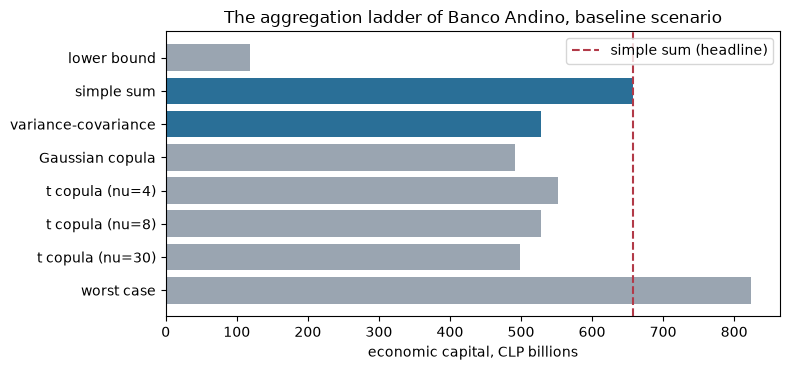

lower-bound          nu=None  capital    118,517  share of the simple sum 0.1801  information-not-capital
simple-sum           nu=None  capital    658,046  share of the simple sum 1.0000  headline-capital
variance-covariance  nu=None  capital    528,106  share of the simple sum 0.8025  information-not-capital
gaussian-copula      nu=None  capital    491,974  share of the simple sum 0.7476  information-not-capital
t-copula             nu=4.0   capital    552,389  share of the simple sum 0.8394  information-not-capital
t-copula             nu=8.0   capital    528,320  share of the simple sum 0.8029  information-not-capital
t-copula             nu=30.0  capital    499,128  share of the simple sum 0.7585  information-not-capital
worst-case           nu=None  capital    823,332  share of the simple sum 1.2512  information-not-capital


In [11]:
# Draw the committed band as bars with the simple sum as a vertical line, and mark the rows recomputed here
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum", "variance-covariance": "variance-covariance",
         "gaussian-copula": "Gaussian copula", "t-copula": "t copula", "worst-case": "worst case"}
labels = [NAMES[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in agg["band"]]
values = [r["capital_clp_m"] / 1e3 for r in agg["band"]]
recomputed = {"simple sum", "variance-covariance"}
colours = ["#2a6f97" if label in recomputed else "#9aa5b1" for label in labels]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(labels[::-1], values[::-1], color=colours[::-1])
ax.axvline(total_simple / 1e3, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_xlabel("economic capital, CLP billions")
ax.set_title("The aggregation ladder of Banco Andino, baseline scenario")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
for r in agg["band"]:
    print(f'{r["method"]:20s} nu={str(r["nu"]):5s} capital {r["capital_clp_m"]:10,.0f}  share of the simple sum {r["diversification_factor"]:.4f}  {r["status"]}')

- **The four capitals add to CLP 658,046 million**, the headline of the case, and the engine's sum equals the committed one.
- **The committed correlation matrix is valid** (smallest eigenvalue 0.5), and the engine refuses the three invalid ones with a reason each.
- **The square-root rule gives CLP 528,106 million**, 80.25 percent of the simple sum, a benefit of 19.75 percent, and equals the committed row. The two limits behave as stated: independence gives 394,019 and perfect dependence returns the simple sum.
- **The benefit is a function of the correlation.** With one common correlation it is 40.1 percent at 0, 17.6 percent at 0.5 and nothing at 1: a diversification benefit is only as credible as the matrix behind it, and that matrix is a convention here.
- **Operational risk gets the largest Euler benefit, 41.6 percent, and market risk the smallest, 22.4 percent.** These benefits are on the expected shortfall of the Gaussian-copula aggregate, so they are not comparable with the 19.75 percent of the variance-covariance total.
- **The worst case, CLP 823,332 million, is 1.2512 times the simple sum.** The sign test is green on the diversified rows (largest factor 0.8394) and red when the worst case is included: the simple sum is not an upper bound for a VaR.
- **The additive overestimate of this case, 33.76 percent, lies inside the published 30 to 40 percent.** The paper's benchmark bank has other weights, so this is a consistency to note and not a validation of Banco Andino.

What this notebook does not show: the copula rows of the band were read, not recomputed, because the document holds summary numbers and not the simulated losses (notebook 02 builds a simulation); and Banco Andino is synthetic, so none of these figures is a statement about a real bank.

## Summary

- Economic capital is the VaR less the expected loss, per risk, over one year at 99.9 percent; the document holds the four numbers of each of the four risks.
- The simple sum is the headline capital; the square-root rule needs a valid correlation matrix, which `check_correlation` enforces.
- The diversification factor is the total over the sum of the capitals; its benefit shrinks to nothing as the correlation rises to 1.
- The Euler contributions add up to the total and give each risk its own benefit.
- A VaR is not subadditive: the committed worst case is above the simple sum, so the sum is not an upper bound, and the sign test turns red when it is included.
- The Rosenberg and Schuermann range is a reference to read beside the result, never a threshold.

**What to try next.** Change one off-diagonal entry of the matrix in step 3 and watch the factor of step 5 move. Then continue with notebook 02, which replaces the square-root rule by copulas and shows where the committed Gaussian and t rows come from.

## References

- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. and Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, in Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- This repository: `docs/contracts/engine/aggregation-api.md` (the engine's aggregation functions) and `docs/design/features/c18/requirements.md` (the requirements of the case).